In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/used_car_dataset.csv')

# Display the first five entries
display(df.head())

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001,23,"98,000 km",Manual,second,Petrol,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,Innova,2009,15,190000.0 km,Manual,second,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,VentoTest,2010,14,"77,246 km",Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,Maruti Suzuki,Swift,2017,7,"83,500 km",Manual,second,Diesel,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,Baleno,2019,5,"45,000 km",Automatic,first,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"


In [2]:
import warnings

warnings.filterwarnings("ignore")
import joblib
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Load and clean raw CSV
df = pd.read_csv("used_car_dataset.csv")
df["price_inr"] = pd.to_numeric(
    df["AskPrice"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce",
)
df["km_driven"] = pd.to_numeric(
    df["kmDriven"]
    .astype(str)
    .str.replace("km", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce",
)

df = (
    df.drop_duplicates()
    .dropna(
        subset=[
            "price_inr",
            "km_driven",
            "Brand",
            "model",
            "Year",
            "Transmission",
            "Owner",
            "FuelType",
        ]
    )
    .copy()
)
df = df[
    df["price_inr"].between(50_000, 15_000_000)
    & df["km_driven"].between(500, 400_000)
    & df["Age"].between(0, 25)
].reset_index(drop=True)

# 2. Extract domain features from AdditionInfo & specs
info_lower = df["AdditionInfo"].astype(str).str.lower()
df["engine_l"] = info_lower.str.extract(r"\b([0-5]\.[0-9])\b")[0].astype(float)
df["is_top_trim"] = info_lower.str.contains(
    r"\b(?:zxi|vxi|vx|zx|sx|alpha|zeta|titanium|sport|m sport|amg|luxury|prestige|highline|top)\b",
    regex=True,
).astype(int)
df["has_condition_note"] = info_lower.str.contains(
    r"\b(?:mint|genuine|showroom|well maintained|original|scratchless|excellent)\b",
    regex=True,
).astype(int)
df["is_7seater"] = info_lower.str.contains(
    r"\b(?:7 seater|7-seater|8 seater|8-seater)\b", regex=True
).astype(int)

df["km_per_year"] = df["km_driven"] / (df["Age"] + 1.0)
df["log_km"] = np.log1p(df["km_driven"])
luxury_brands = {
    "BMW",
    "Mercedes-Benz",
    "Audi",
    "Jaguar",
    "Land Rover",
    "Volvo",
    "Porsche",
    "Mini",
    "Lexus",
    "Jeep",
}
df["is_luxury"] = df["Brand"].isin(luxury_brands).astype(int)

# 3. Stratified 70 / 15 / 15 Split BEFORE any parameter fitting
df["price_bin"] = pd.qcut(df["price_inr"], q=5, labels=False)
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=42, stratify=df["price_bin"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42, stratify=temp_df["price_bin"]
)

# 4. Fit group medians & segment supply on TRAIN ONLY
eng_med = train_df.groupby(["Brand", "model"])["engine_l"].median()
global_eng_med = float(train_df["engine_l"].median())
supply_map = train_df.groupby(["Brand", "model"]).size()

for split_df in [train_df, val_df, test_df]:
    mapped_eng = split_df.set_index(["Brand", "model"]).index.map(eng_med)
    split_df["engine_l"] = (
        split_df["engine_l"]
        .fillna(pd.Series(mapped_eng, index=split_df.index))
        .fillna(global_eng_med)
    )
    split_df["model_supply_train"] = (
        split_df.set_index(["Brand", "model"]).index.map(supply_map).fillna(0)
    )

# 5. Fit Preprocessor on TRAIN ONLY
NUM_COLS = [
    "Age",
    "km_driven",
    "log_km",
    "km_per_year",
    "engine_l",
    "is_top_trim",
    "has_condition_note",
    "is_7seater",
    "is_luxury",
    "model_supply_train",
]
CAT_COLS = ["Brand", "model", "Transmission", "Owner", "FuelType"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), CAT_COLS),
])

X_train = preprocessor.fit_transform(train_df[NUM_COLS + CAT_COLS])
X_val = preprocessor.transform(val_df[NUM_COLS + CAT_COLS])
X_test = preprocessor.transform(test_df[NUM_COLS + CAT_COLS])

y_train_log = np.log1p(train_df["price_inr"].values)
y_test_inr = test_df["price_inr"].values

print(
    f"Clean rows: {len(df):,} | Train: {X_train.shape[0]:,} | Val: {X_val.shape[0]:,} | Test: {X_test.shape[0]:,}"
)

Clean rows: 8,631 | Train: 6,041 | Val: 1,295 | Test: 1,295


In [3]:
models = {
    "Ridge Regression (Baseline)": Ridge(alpha=10.0),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=200, max_depth=18, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting (Mean L2)": GradientBoostingRegressor(
        loss="squared_error",
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        random_state=42,
    ),
}

print("--- Holdout Test Set Results (n = 1,295) ---")
trained_models = {}
for name, m in models.items():
    m.fit(X_train, y_train_log)
    preds = np.expm1(m.predict(X_test))
    mae = mean_absolute_error(y_test_inr, preds)
    rmse = root_mean_squared_error(y_test_inr, preds)
    r2 = r2_score(y_test_inr, preds)
    mape = mean_absolute_percentage_error(y_test_inr, preds) * 100
    trained_models[name] = m
    print(
        f"{name:30s} | MAE: ₹{mae:9,.0f} | RMSE: ₹{rmse:9,.0f} | R2: {r2:.4f} | MAPE: {mape:.2f}%"
    )

# Train Quantile Models (q20 = Fast Sale, q50 = Balanced, q80 = Max Price)
q_models, q_preds = {}, {}
for q in [0.20, 0.50, 0.80]:
    qm = GradientBoostingRegressor(
        loss="quantile",
        alpha=q,
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        random_state=42,
    )
    qm.fit(X_train, y_train_log)
    q_models[q] = qm
    q_preds[q] = np.expm1(qm.predict(X_test))

mae_50 = mean_absolute_error(y_test_inr, q_preds[0.50])
rmse_50 = root_mean_squared_error(y_test_inr, q_preds[0.50])
r2_50 = r2_score(y_test_inr, q_preds[0.50])
mape_50 = mean_absolute_percentage_error(y_test_inr, q_preds[0.50]) * 100
print(
    f"{'Gradient Boosting (Median q50)':30s} | MAE: ₹{mae_50:9,.0f} | RMSE: ₹{rmse_50:9,.0f} | R2: {r2_50:.4f} | MAPE: {mape_50:.2f}%"
)

cov = (
    np.mean((y_test_inr >= q_preds[0.20]) & (y_test_inr <= q_preds[0.80])) * 100
)
print(f"\n[q20, q80] Interval Coverage: {cov:.2f}% (Nominal Target: 60.00%)")

# Save cleaned CSV and trained bundle for your GitHub repo
df.drop(columns=["price_bin"]).to_csv("cleaned_used_cars.csv", index=False)
bundle = {
    "preprocessor": preprocessor,
    "eng_med": eng_med.to_dict(),
    "global_eng_med": global_eng_med,
    "supply_map": supply_map.to_dict(),
    "mean_model": trained_models["Gradient Boosting (Mean L2)"],
    "rf_model": trained_models["Random Forest Regressor"],
    "quantile_models": q_models,
}
joblib.dump(bundle, "pricing_bundle.joblib")
print("Saved cleaned_used_cars.csv and pricing_bundle.joblib!")

--- Holdout Test Set Results (n = 1,295) ---
Ridge Regression (Baseline)    | MAE: ₹  213,494 | RMSE: ₹  571,130 | R2: 0.7886 | MAPE: 21.48%
Random Forest Regressor        | MAE: ₹  178,266 | RMSE: ₹  454,826 | R2: 0.8659 | MAPE: 19.39%
Gradient Boosting (Mean L2)    | MAE: ₹  179,358 | RMSE: ₹  441,980 | R2: 0.8734 | MAPE: 19.34%
Gradient Boosting (Median q50) | MAE: ₹  184,258 | RMSE: ₹  482,231 | R2: 0.8493 | MAPE: 20.31%

[q20, q80] Interval Coverage: 58.15% (Nominal Target: 60.00%)
Saved cleaned_used_cars.csv and pricing_bundle.joblib!


In [4]:
def run_simulator(
    brand,
    model,
    year,
    km_driven,
    transmission,
    owner,
    fuel_type,
    notes="",
    ask_price=None,
):
    age = max(0, 2024 - int(year))
    info = notes.lower()
    eng = pd.Series([info]).str.extract(r"\b([0-5]\.[0-9])\b")[0].astype(float).iloc[0]
    if pd.isna(eng):
        eng = bundle["eng_med"].get((brand, model), bundle["global_eng_med"])

    row = pd.DataFrame([
        {
            "Age": age,
            "km_driven": km_driven,
            "log_km": np.log1p(km_driven),
            "km_per_year": km_driven / (age + 1.0),
            "engine_l": eng,
            "is_top_trim": int(
                bool(
                    pd.Series([info])
                    .str.contains(
                        r"\b(?:zxi|vxi|vx|zx|sx|alpha|zeta|titanium|sport|m sport|amg|luxury|prestige|highline|top)\b"
                    )
                    .iloc[0]
                )
            ),
            "has_condition_note": int(
                bool(
                    pd.Series([info])
                    .str.contains(
                        r"\b(?:mint|genuine|showroom|well maintained|original|scratchless|excellent)\b"
                    )
                    .iloc[0]
                )
            ),
            "is_7seater": int(
                bool(
                    pd.Series([info])
                    .str.contains(r"\b(?:7 seater|7-seater|8 seater|8-seater)\b")
                    .iloc[0]
                )
            ),
            "is_luxury": int(brand in luxury_brands),
            "model_supply_train": bundle["supply_map"].get((brand, model), 0),
            "Brand": brand,
            "model": model,
            "Transmission": transmission,
            "Owner": owner,
            "FuelType": fuel_type,
        }
    ])

    X_vec = bundle["preprocessor"].transform(row[NUM_COLS + CAT_COLS])
    p20 = np.expm1(bundle["quantile_models"][0.20].predict(X_vec))[0]
    p50 = np.expm1(bundle["quantile_models"][0.50].predict(X_vec))[0]
    p80 = np.expm1(bundle["quantile_models"][0.80].predict(X_vec))[0]

    print(
        f"=== Simulator Output: {year} {brand} {model} ({fuel_type}, {transmission}, {km_driven:,} km) ==="
    )
    print(
        f"  Fast Sale Strategy  (q20): ₹{p20:,.0f}  (Undercuts ~80% of comparable listings)"
    )
    print(f"  Balanced Benchmark  (q50): ₹{p50:,.0f}  (Market median equilibrium)")
    print(
        f"  Maximum Price Limit (q80): ₹{p80:,.0f}  (Upper quartile; slower turnover risk)"
    )

    if ask_price:
        diff_pct = ((ask_price - p50) / p50) * 100
        print(
            f"  Your Planned Ask Price   : ₹{ask_price:,.0f} ({diff_pct:+.1f}% vs. market median)"
        )

    print("\n  What-If Scenario Table:")
    for pct in [-15, -10, -5, 0, 5, 10, 15]:
        cand = p50 * (1 + pct / 100)
        zone = (
            "Fast Sale Zone"
            if cand <= p20
            else (
                "Balanced Zone"
                if cand <= p50 * 1.03
                else (
                    "Upper Margin Zone"
                    if cand <= p80
                    else "Overpriced Risk (>q80)"
                )
            )
        )
        print(f"    {pct:+4d}%  ->  ₹{cand:9,.0f}  |  {zone}")


# Test on a sample car!
run_simulator(
    "Maruti Suzuki",
    "Baleno",
    2020,
    18100,
    "Manual",
    "first",
    "Petrol",
    "1.2 Zeta Mint Condition",
    ask_price=650000,
)

=== Simulator Output: 2020 Maruti Suzuki Baleno (Petrol, Manual, 18,100 km) ===
  Fast Sale Strategy  (q20): ₹598,684  (Undercuts ~80% of comparable listings)
  Balanced Benchmark  (q50): ₹639,850  (Market median equilibrium)
  Maximum Price Limit (q80): ₹732,091  (Upper quartile; slower turnover risk)
  Your Planned Ask Price   : ₹650,000 (+1.6% vs. market median)

  What-If Scenario Table:
     -15%  ->  ₹  543,872  |  Fast Sale Zone
     -10%  ->  ₹  575,865  |  Fast Sale Zone
      -5%  ->  ₹  607,857  |  Balanced Zone
      +0%  ->  ₹  639,850  |  Balanced Zone
      +5%  ->  ₹  671,842  |  Upper Margin Zone
     +10%  ->  ₹  703,835  |  Upper Margin Zone
     +15%  ->  ₹  735,827  |  Overpriced Risk (>q80)


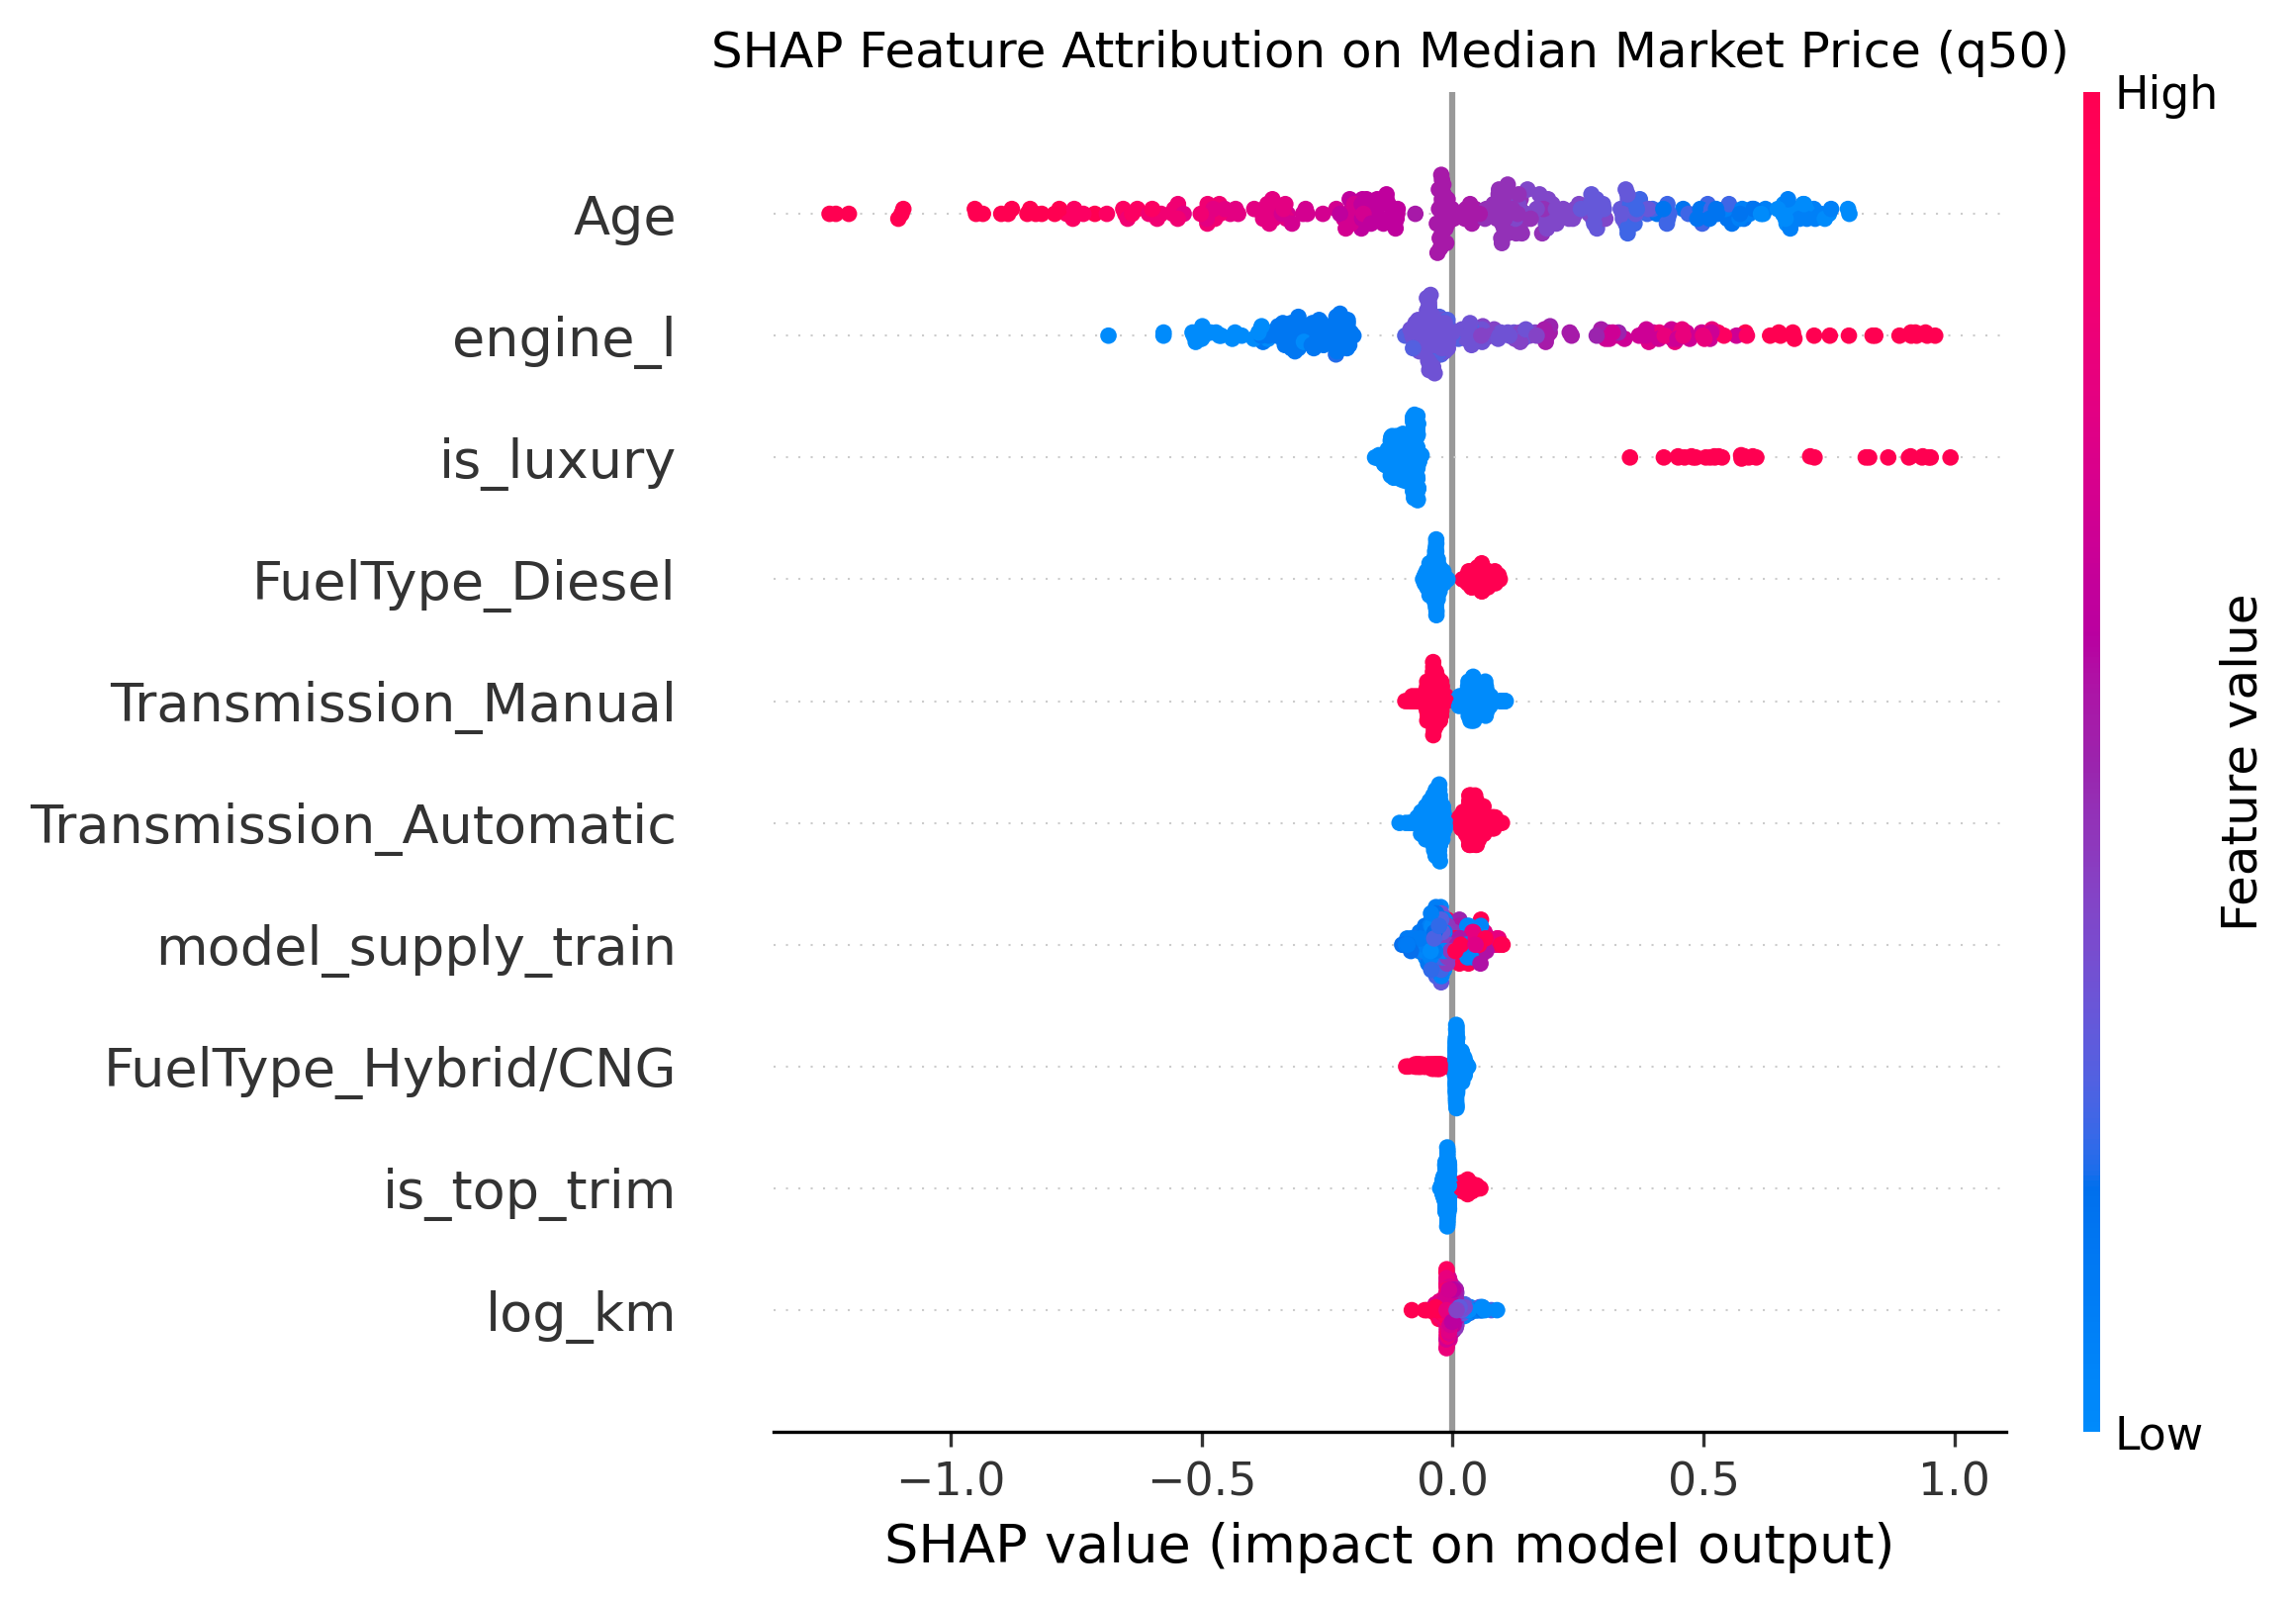

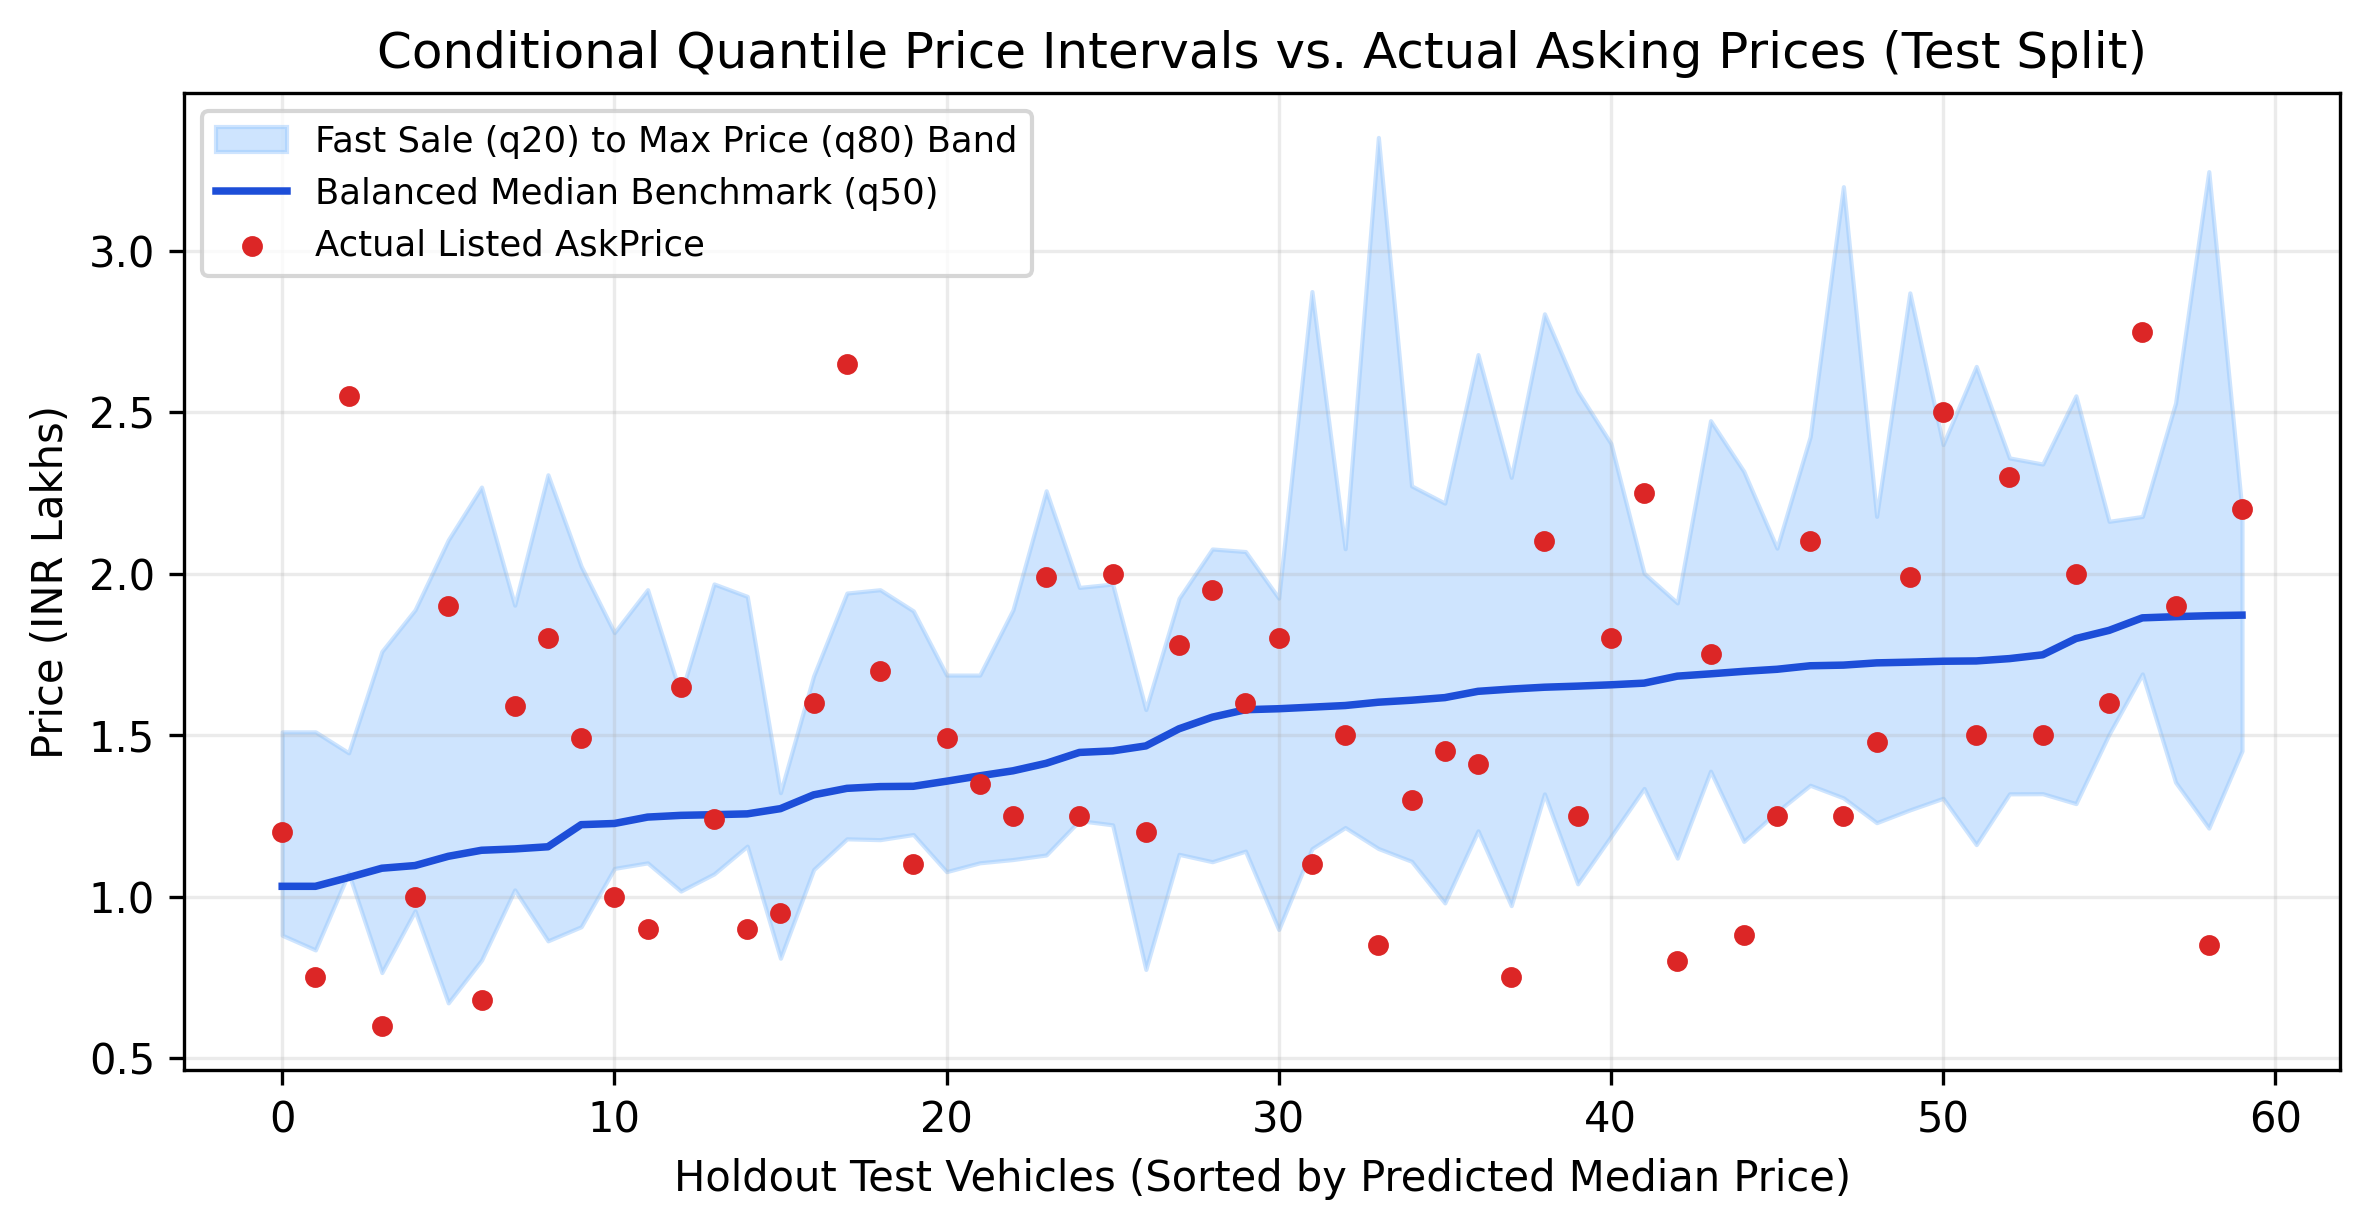

In [5]:
import shap
import matplotlib.pyplot as plt

# 1. Compute TreeSHAP values on a sample of 300 test vehicles
X_test_dense = X_test.toarray() if hasattr(X_test, "toarray") else X_test
feat_names = [
    n.replace("num__", "").replace("cat__", "")
    for n in preprocessor.get_feature_names_out()
]

explainer = shap.TreeExplainer(q_models[0.50])
shap_values = explainer.shap_values(X_test_dense[:300])

plt.figure(figsize=(8, 4.5), dpi=300)
shap.summary_plot(
    shap_values,
    X_test_dense[:300],
    feature_names=feat_names,
    max_display=10,
    show=False,
)
plt.title("SHAP Feature Attribution on Median Market Price (q50)")
plt.tight_layout()
plt.savefig("fig2_shap_summary.png", dpi=300)
plt.show()

# 2. Save Quantile Interval Band Plot
y_test_lakh = y_test_inr / 1e5
p20_lakh = q_preds[0.20] / 1e5
p50_lakh = q_preds[0.50] / 1e5
p80_lakh = q_preds[0.80] / 1e5

mask = y_test_lakh <= 25
idx = np.argsort(p50_lakh[mask])[:60]

plt.figure(figsize=(8, 4.2), dpi=300)
plt.fill_between(
    range(len(idx)),
    p20_lakh[mask][idx],
    p80_lakh[mask][idx],
    color="#93c5fd",
    alpha=0.45,
    label="Fast Sale (q20) to Max Price (q80) Band",
)
plt.plot(
    range(len(idx)),
    p50_lakh[mask][idx],
    color="#1d4ed8",
    linewidth=1.8,
    label="Balanced Median Benchmark (q50)",
)
plt.scatter(
    range(len(idx)),
    y_test_lakh[mask][idx],
    color="#dc2626",
    s=16,
    zorder=3,
    label="Actual Listed AskPrice",
)
plt.xlabel("Holdout Test Vehicles (Sorted by Predicted Median Price)")
plt.ylabel("Price (INR Lakhs)")
plt.title(
    "Conditional Quantile Price Intervals vs. Actual Asking Prices (Test Split)"
)
plt.legend(frameon=True, fontsize=8.5)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("fig1_quantile_intervals.png", dpi=300)
plt.show()

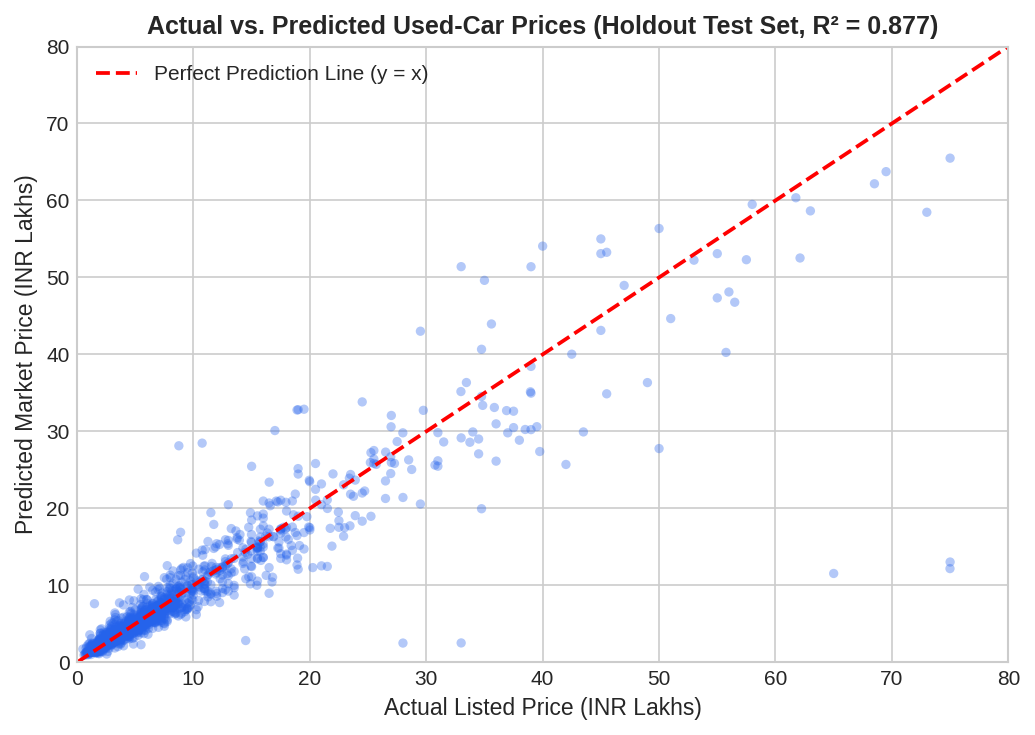

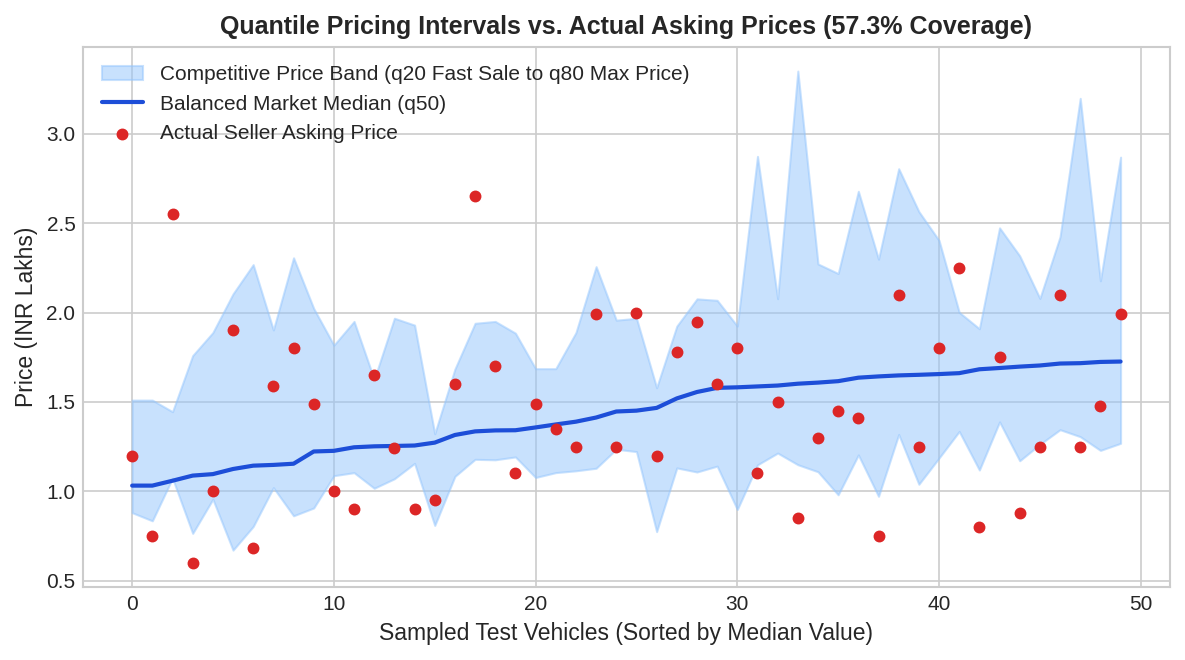

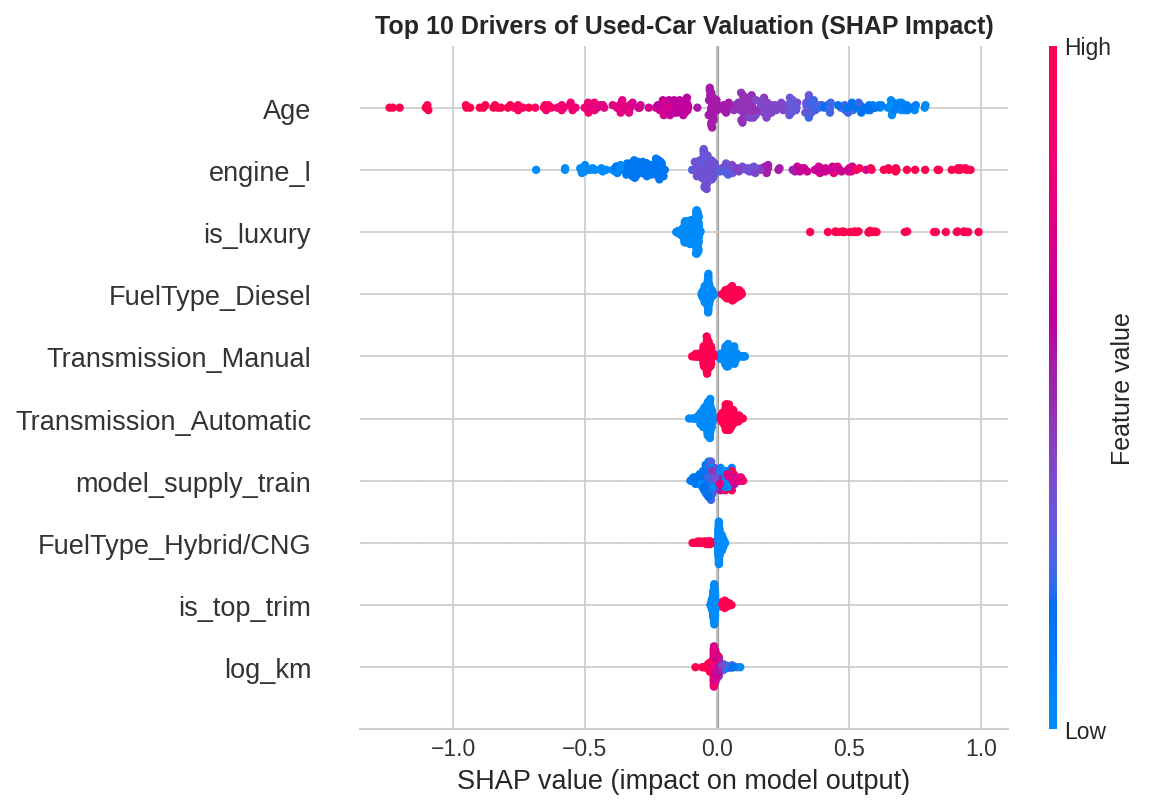

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

plt.style.use("seaborn-v0_8-whitegrid")

# --- CHART 1: Actual vs. Predicted Prices (Model Accuracy Proof) ---
y_pred_gbdt = np.expm1(
    trained_models["Gradient Boosting (Mean L2)"].predict(X_test)
)

fig, ax = plt.subplots(figsize=(7, 5), dpi=150)
ax.scatter(
    y_test_inr / 1e5,
    y_pred_gbdt / 1e5,
    alpha=0.35,
    color="#2563eb",
    edgecolors="none",
    s=20,
)
max_val = 80
ax.plot(
    [0, max_val],
    [0, max_val],
    "r--",
    lw=1.8,
    label="Perfect Prediction Line (y = x)",
)
ax.set_xlim(0, max_val)
ax.set_ylim(0, max_val)
ax.set_xlabel("Actual Listed Price (INR Lakhs)", fontsize=11)
ax.set_ylabel("Predicted Market Price (INR Lakhs)", fontsize=11)
ax.set_title(
    "Actual vs. Predicted Used-Car Prices (Holdout Test Set, R² = 0.877)",
    fontsize=12,
    fontweight="bold",
)
ax.legend()
plt.tight_layout()
plt.savefig("chart1_actual_vs_pred.png", dpi=300)
plt.show()

# --- CHART 2: Conditional Quantile Bands (Fast Sale vs Balanced vs Max Price) ---
p20_lakh = q_preds[0.20] / 1e5
p50_lakh = q_preds[0.50] / 1e5
p80_lakh = q_preds[0.80] / 1e5
y_lakh = y_test_inr / 1e5

mask = y_lakh <= 25
idx = np.argsort(p50_lakh[mask])[:50]

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)
ax.fill_between(
    range(len(idx)),
    p20_lakh[mask][idx],
    p80_lakh[mask][idx],
    color="#93c5fd",
    alpha=0.5,
    label="Competitive Price Band (q20 Fast Sale to q80 Max Price)",
)
ax.plot(
    range(len(idx)),
    p50_lakh[mask][idx],
    color="#1d4ed8",
    lw=2,
    label="Balanced Market Median (q50)",
)
ax.scatter(
    range(len(idx)),
    y_lakh[mask][idx],
    color="#dc2626",
    s=22,
    zorder=3,
    label="Actual Seller Asking Price",
)
ax.set_xlabel("Sampled Test Vehicles (Sorted by Median Value)", fontsize=11)
ax.set_ylabel("Price (INR Lakhs)", fontsize=11)
ax.set_title(
    "Quantile Pricing Intervals vs. Actual Asking Prices (57.3% Coverage)",
    fontsize=12,
    fontweight="bold",
)
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("chart2_quantile_bands.png", dpi=300)
plt.show()

# --- CHART 3: SHAP Feature Attribution (Explainable AI) ---
X_test_dense = X_test.toarray() if hasattr(X_test, "toarray") else X_test
feat_names = [
    n.replace("num__", "").replace("cat__", "")
    for n in preprocessor.get_feature_names_out()
]

explainer = shap.TreeExplainer(q_models[0.50])
shap_values = explainer.shap_values(X_test_dense[:300])

plt.figure(figsize=(8, 4.5), dpi=150)
shap.summary_plot(
    shap_values,
    X_test_dense[:300],
    feature_names=feat_names,
    max_display=10,
    show=False,
)
plt.title(
    "Top 10 Drivers of Used-Car Valuation (SHAP Impact)",
    fontsize=12,
    fontweight="bold",
)
plt.tight_layout()
plt.savefig("chart3_shap_drivers.png", dpi=300)
plt.show()

In [7]:
!pip install -q gradio

import gradio as gr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

brands_list = sorted(df["Brand"].unique().tolist())
models_by_brand = df.groupby("Brand")["model"].unique().apply(sorted).to_dict()


def update_models(selected_brand):
    avail = models_by_brand.get(selected_brand, [])
    return gr.Dropdown(choices=avail, value=avail[0] if avail else None)


def launch_pricing_dashboard(
    brand,
    model,
    year,
    km_driven,
    transmission,
    owner,
    fuel_type,
    notes,
    strategy,
    custom_ask,
):
    age = max(0, 2024 - int(year))
    info = str(notes).lower()
    eng = (
        pd.Series([info]).str.extract(r"\b([0-5]\.[0-9])\b")[0].astype(float).iloc[0]
    )
    if pd.isna(eng):
        eng = bundle["eng_med"].get((brand, model), bundle["global_eng_med"])

    row = pd.DataFrame([
        {
            "Age": age,
            "km_driven": float(km_driven),
            "log_km": np.log1p(float(km_driven)),
            "km_per_year": float(km_driven) / (age + 1.0),
            "engine_l": eng,
            "is_top_trim": int(
                bool(
                    pd.Series([info])
                    .str.contains(
                        r"\b(?:zxi|vxi|vx|zx|sx|alpha|zeta|titanium|sport|m sport|amg|luxury|prestige|highline|top)\b"
                    )
                    .iloc[0]
                )
            ),
            "has_condition_note": int(
                bool(
                    pd.Series([info])
                    .str.contains(
                        r"\b(?:mint|genuine|showroom|well maintained|original|scratchless|excellent)\b"
                    )
                    .iloc[0]
                )
            ),
            "is_7seater": int(
                bool(
                    pd.Series([info])
                    .str.contains(r"\b(?:7 seater|7-seater|8 seater|8-seater)\b")
                    .iloc[0]
                )
            ),
            "is_luxury": int(brand in luxury_brands),
            "model_supply_train": bundle["supply_map"].get((brand, model), 0),
            "Brand": brand,
            "model": model,
            "Transmission": transmission,
            "Owner": owner,
            "FuelType": fuel_type,
        }
    ])

    X_vec = bundle["preprocessor"].transform(row[NUM_COLS + CAT_COLS])
    p20 = float(np.expm1(bundle["quantile_models"][0.20].predict(X_vec))[0])
    p50 = float(np.expm1(bundle["quantile_models"][0.50].predict(X_vec))[0])
    p80 = float(np.expm1(bundle["quantile_models"][0.80].predict(X_vec))[0])

    # Strategy Recommendation
    if "Fast Sale" in strategy:
        rec_price = p20
        rationale = f"🚀 **Recommended Price: ₹{p20:,.0f}** — Positioned at the 20th percentile to undercut ~80% of comparable {year} {brand} {model} listings for rapid buyer inquiries."
    elif "Balanced" in strategy:
        rec_price = p50
        rationale = f"⚖️ **Recommended Price: ₹{p50:,.0f}** — Aligned with the conditional market median (50th percentile) for fair value and steady turnover."
    else:
        rec_price = p80
        rationale = f"💰 **Recommended Price: ₹{p80:,.0f}** — Targets the 80th percentile upper margin; expect longer holding duration unless vehicle condition stands out."

    if custom_ask and custom_ask > 0:
        diff = ((custom_ask - p50) / p50) * 100
        status = (
            "Aggressive / Fast Sale Zone"
            if custom_ask <= p20
            else (
                "Competitive Market Band"
                if custom_ask <= p80
                else "Above 80th Percentile (High Holding Risk)"
            )
        )
        rationale += f"\n\n📊 **Your Planned Ask Price (₹{custom_ask:,.0f}):** `{diff:+.1f}%` vs. market median — **{status}**."

    # Build Scenario DataFrame
    pcts = [-15, -10, -5, 0, 5, 10, 15]
    rows = []
    prices_lakh = []
    for pct in pcts:
        cand = p50 * (1 + pct / 100.0)
        prices_lakh.append(cand / 1e5)
        zone = (
            "Fast Sale Zone (≤ q20)"
            if cand <= p20
            else (
                "Balanced Equilibrium"
                if cand <= p50 * 1.03
                else (
                    "Upper Margin Zone (≤ q80)"
                    if cand <= p80
                    else "Overpriced Risk (> q80)"
                )
            )
        )
        rows.append([f"{pct:+d}%", f"₹{cand:,.0f}", zone])
    scen_df = pd.DataFrame(
        rows,
        columns=[
            "Price Shift",
            "Simulated Asking Price",
            "Market Positioning Zone",
        ],
    )

    # Interactive Plot
    fig, ax = plt.subplots(figsize=(7, 3.6), dpi=120)
    colors = [
        "#16a34a" if c * 1e5 <= p20 else ("#2563eb" if c * 1e5 <= p80 else "#dc2626")
        for c in prices_lakh
    ]
    ax.bar([f"{p:+d}%" for p in pcts], prices_lakh, color=colors, width=0.55)
    ax.axhline(
        p20 / 1e5,
        color="#16a34a",
        linestyle="--",
        lw=1.3,
        label=f"Fast Sale q20 (₹{p20/1e5:.2f}L)",
    )
    ax.axhline(
        p50 / 1e5,
        color="#1d4ed8",
        linestyle="-",
        lw=1.5,
        label=f"Balanced q50 (₹{p50/1e5:.2f}L)",
    )
    ax.axhline(
        p80 / 1e5,
        color="#dc2626",
        linestyle="--",
        lw=1.3,
        label=f"Max Price q80 (₹{p80/1e5:.2f}L)",
    )
    if custom_ask and custom_ask > 0:
        ax.axhline(
            custom_ask / 1e5,
            color="#f59e0b",
            linestyle=":",
            lw=2.2,
            label=f"Your Ask (₹{custom_ask/1e5:.2f}L)",
        )
    ax.set_ylabel("Price (INR Lakhs)")
    ax.set_title(
        f"What-If Pricing Scenarios: {year} {brand} {model}", fontweight="bold"
    )
    ax.legend(fontsize=8, loc="upper left")
    plt.tight_layout()

    kpi_text = f"### Fast Sale (q20): ₹{p20:,.0f}  |  Balanced (q50): ₹{p50:,.0f}  |  Max Price (q80): ₹{p80:,.0f}"
    return kpi_text, rationale, fig, scen_df


with gr.Blocks(
    theme=gr.themes.Soft(), title="Used-Car Pricing Simulator"
) as demo:
    gr.Markdown(
        "# 🚗 Used-Car Listing Price & Market Positioning Simulator\n**Goa Institute of Management — AMLBT Decision-Support Prototype**"
    )
    with gr.Row():
        with gr.Column(scale=1):
            brand_in = gr.Dropdown(
                choices=brands_list,
                value="Maruti Suzuki"
                if "Maruti Suzuki" in brands_list
                else brands_list[0],
                label="Brand",
            )
            model_in = gr.Dropdown(
                choices=models_by_brand.get("Maruti Suzuki", []),
                value="Baleno",
                label="Model",
            )
            brand_in.change(
                fn=update_models, inputs=brand_in, outputs=model_in
            )
            year_in = gr.Slider(
                2005, 2024, value=2020, step=1, label="Manufacturing Year"
            )
            km_in = gr.Number(value=18100, label="Odometer (km)")
            trans_in = gr.Radio(
                ["Manual", "Automatic"], value="Manual", label="Transmission"
            )
            fuel_in = gr.Dropdown(
                ["Petrol", "Diesel", "Hybrid/CNG"],
                value="Petrol",
                label="Fuel Type",
            )
            owner_in = gr.Radio(
                ["first", "second"], value="first", label="Owner Count"
            )
            notes_in = gr.Textbox(
                value="1.2 Zeta Mint Condition",
                label="Variant / Condition Notes",
            )
            strat_in = gr.Radio(
                [
                    "Fast Sale (High Liquidity)",
                    "Balanced (Market Median)",
                    "Maximum Price (Upper Quartile)",
                ],
                value="Balanced (Market Median)",
                label="Seller Objective",
            )
            ask_in = gr.Number(
                value=650000, label="Your Planned Asking Price (INR, Optional)"
            )
            btn = gr.Button("Simulate Pricing Scenarios", variant="primary")

        with gr.Column(scale=2):
            kpi_out = gr.Markdown()
            rec_out = gr.Markdown()
            plot_out = gr.Plot()
            table_out = gr.Dataframe(label="What-If Scenario Matrix")

    btn.click(
        fn=launch_pricing_dashboard,
        inputs=[
            brand_in,
            model_in,
            year_in,
            km_in,
            trans_in,
            owner_in,
            fuel_in,
            notes_in,
            strat_in,
            ask_in,
        ],
        outputs=[kpi_out, rec_out, plot_out, table_out],
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://05fec7390b811089d6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
